# TelcoPeople — Modélisation spécialisée des départs visibles et silencieux

Ce notebook teste une architecture à deux modèles :

- **modèle visible** : apprend les départs accompagnés de signaux RH observables ;
- **modèle silencieux** : apprend les départs sans signaux forts apparents ;
- **fusion** : combine les deux probabilités pour produire le risque final de départ.

Cette approche reste expérimentale. Les départs silencieux sont peu nombreux et peuvent dépendre de facteurs absents des données. Le second modèle ne sera conservé que s’il améliore réellement la validation temporelle.

## 1. Importation des bibliothèques

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    roc_auc_score, classification_report
)
from catboost import CatBoostClassifier

pd.set_option("display.max_columns", 150)
sns.set_theme(style="whitegrid")

## 2. Chargement des données

In [2]:
CHEMIN = "../data/raw/"
train = pd.read_csv(CHEMIN + "telcopeople_train.csv")
test = pd.read_csv(CHEMIN + "telcopeople_test.csv")

print("Train :", train.shape)
print("Test :", test.shape)

Train : (5444, 42)
Test : (1507, 41)


## 3. Préparation métier

La fonction reprend les variables validées dans les notebooks précédents.

In [3]:
def preparer_donnees(df):
    df = df.copy()

    df["ville_affectation"] = df["ville_affectation"].fillna("INCONNU").str.strip().str.title()
    df["departement"] = df["departement"].fillna("INCONNU").str.strip().str.upper().str.replace("DEPT", "DEP", regex=False)
    df["contrat"] = df["contrat"].fillna("INCONNU").str.strip().str.upper().str.replace(".", "", regex=False)
    df["niveau_etude"] = df["niveau_etude"].fillna("INCONNU").str.strip().str.upper().str.replace(" ", "", regex=False).str.replace("BAC2", "BAC+2", regex=False)
    for col in ["genre", "poste", "grade", "code_site", "source_sirh"]:
        df[col] = df[col].fillna("INCONNU").astype(str).str.strip().str.upper()

    for col in ["date_reference", "date_naissance", "date_embauche", "date_derniere_promotion", "date_derniere_absence"]:
        df[col] = pd.to_datetime(df[col], format="mixed", dayfirst=True, errors="coerce")

    df["salaire_mensuel"] = pd.to_numeric(
        df["salaire_mensuel"].astype(str).str.replace("FCFA", "", regex=False).str.replace(" ", "", regex=False),
        errors="coerce"
    )

    df["age"] = (df["date_reference"] - df["date_naissance"]).dt.days / 365.25
    df["anciennete"] = (df["date_reference"] - df["date_embauche"]).dt.days / 365.25
    df["annees_depuis_promotion"] = (df["date_reference"] - df["date_derniere_promotion"]).dt.days / 365.25
    df["jours_depuis_absence"] = (df["date_reference"] - df["date_derniere_absence"]).dt.days

    df["ratio_salaire_reference"] = df["salaire_mensuel"] / df["reference_salaire_grade"]
    df["ecart_salaire_reference"] = df["salaire_mensuel"] - df["reference_salaire_grade"]
    df["evolution_salaire"] = df["salaire_mensuel"] - df["salaire_12m_avant"]
    df["taux_evolution_salaire"] = df["evolution_salaire"] / df["salaire_12m_avant"].replace(0, np.nan)

    df["engagement_moyen"] = df[["engagement_actuel", "engagement_precedent"]].mean(axis=1)
    df["evolution_engagement"] = df["engagement_actuel"] - df["engagement_precedent"]
    df["performance_moyenne"] = df[["performance_actuelle", "performance_precedente"]].mean(axis=1)
    df["evolution_performance"] = df["performance_actuelle"] - df["performance_precedente"]

    df["jours_abs_6m"] = df[[f"jours_abs_m{i}" for i in range(1, 7)]].sum(axis=1)
    df["nb_abs_6m"] = df[[f"nb_abs_m{i}" for i in range(1, 7)]].sum(axis=1)
    df["abs_non_just_6m"] = df[[f"abs_non_just_m{i}" for i in range(1, 7)]].sum(axis=1)
    df["jours_abs_recents"] = df[["jours_abs_m1", "jours_abs_m2", "jours_abs_m3"]].sum(axis=1)
    df["jours_abs_anciens"] = df[["jours_abs_m4", "jours_abs_m5", "jours_abs_m6"]].sum(axis=1)
    df["tendance_absence"] = df["jours_abs_recents"] - df["jours_abs_anciens"]

    df["jamais_promu"] = df["date_derniere_promotion"].isna().astype(int)
    df["absence_non_renseignee"] = df["date_derniere_absence"].isna().astype(int)
    df["engagement_manquant"] = df["engagement_actuel"].isna().astype(int)
    df["performance_manquante"] = df["performance_actuelle"].isna().astype(int)

    return df.replace([np.inf, -np.inf], np.nan)

## 4. Préparation et séparation temporelle

In [4]:
train_prepare = preparer_donnees(train)
test_prepare = preparer_donnees(test)

DATE_VALIDATION = pd.Timestamp("2024-06-30")
masque_train = train_prepare["date_reference"] < DATE_VALIDATION
masque_validation = train_prepare["date_reference"] == DATE_VALIDATION

print("Apprentissage :", masque_train.sum())
print("Validation :", masque_validation.sum())

Apprentissage : 4130
Validation : 1314


## 5. Signaux comportementaux

Ces signaux servent à définir les départs visibles. Cette définition est opérationnelle, pas une vérité absolue.

In [5]:
for df in [train_prepare, test_prepare]:
    df["engagement_faible"] = (df["engagement_actuel"] < 3).astype(int)
    df["salaire_sous_reference"] = (df["ratio_salaire_reference"] < 0.95).astype(int)
    df["mecanisme_desengagement"] = (
        (df["engagement_actuel"] < 3).astype(int) +
        (df["evolution_engagement"] < -0.30).astype(int) +
        (df["tendance_absence"] > 1).astype(int)
    )
    df["mecanisme_stagnation"] = (
        (df["anciennete"] >= 4).astype(int) +
        (((df["annees_depuis_promotion"] >= 2) | (df["jamais_promu"] == 1))).astype(int) +
        (df["performance_moyenne"] >= 3.5).astype(int)
    )

## 6. Variables de clustering et d’anomalie

Les modèles non supervisés sont ajustés uniquement sur l’apprentissage temporel.

In [6]:
variables_num_cluster = [
    "age", "anciennete", "annees_depuis_promotion", "ratio_salaire_reference",
    "taux_evolution_salaire", "engagement_actuel", "engagement_precedent",
    "engagement_moyen", "performance_actuelle", "performance_precedente",
    "performance_moyenne", "jours_abs_6m", "nb_abs_6m", "abs_non_just_6m",
    "tendance_absence", "taille_departement"
]
variables_cat_cluster = ["contrat", "grade", "departement", "code_site"]
variables_cluster = variables_num_cluster + variables_cat_cluster

preprocesseur = ColumnTransformer([
    ("num", Pipeline([
        ("imputation", SimpleImputer(strategy="median")),
        ("standardisation", StandardScaler())
    ]), variables_num_cluster),
    ("cat", Pipeline([
        ("imputation", SimpleImputer(strategy="most_frequent")),
        ("encodage", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), variables_cat_cluster)
])

Z_train = preprocesseur.fit_transform(train_prepare.loc[masque_train, variables_cluster])
Z_val = preprocesseur.transform(train_prepare.loc[masque_validation, variables_cluster])
Z_test = preprocesseur.transform(test_prepare[variables_cluster])

kmeans = KMeans(n_clusters=7, random_state=42, n_init=20).fit(Z_train)
isolation = IsolationForest(n_estimators=500, contamination=0.03, random_state=42, n_jobs=-1).fit(Z_train)

## 7. Ajout des variables non supervisées

In [7]:
def ajouter_non_supervise(df, masque, matrice):
    distances = kmeans.transform(matrice)
    distances_triees = np.sort(distances, axis=1)
    df.loc[masque, "cluster_rh"] = distances.argmin(axis=1).astype(str)
    df.loc[masque, "distance_cluster"] = distances_triees[:, 0]
    df.loc[masque, "marge_cluster"] = distances_triees[:, 1] - distances_triees[:, 0]
    df.loc[masque, "score_anomalie"] = -isolation.score_samples(matrice)

ajouter_non_supervise(train_prepare, masque_train, Z_train)
ajouter_non_supervise(train_prepare, masque_validation, Z_val)

masque_test = pd.Series(True, index=test_prepare.index)
ajouter_non_supervise(test_prepare, masque_test, Z_test)

train_prepare["cluster_rh"] = train_prepare["cluster_rh"].astype(str)
test_prepare["cluster_rh"] = test_prepare["cluster_rh"].astype(str)

## 8. Création des cibles spécialisées

Chaque observation reçoit trois cibles :

- `target` : tout départ ;
- `target_visible` : départ avec signal visible ;
- `target_silencieux` : départ sans signal visible.

Les non-départs valent zéro dans les deux cibles spécialisées.

In [8]:
seuil_anomalie = train_prepare.loc[masque_train, "score_anomalie"].quantile(0.90)

train_prepare["signal_visible"] = (
    (train_prepare["mecanisme_desengagement"] >= 2) |
    (train_prepare["salaire_sous_reference"] == 1) |
    (train_prepare["mecanisme_stagnation"] >= 2) |
    (train_prepare["score_anomalie"] >= seuil_anomalie)
).astype(int)

test_prepare["signal_visible"] = (
    (test_prepare["mecanisme_desengagement"] >= 2) |
    (test_prepare["salaire_sous_reference"] == 1) |
    (test_prepare["mecanisme_stagnation"] >= 2) |
    (test_prepare["score_anomalie"] >= seuil_anomalie)
).astype(int)

train_prepare["target_visible"] = (
    (train_prepare["target"] == 1) & (train_prepare["signal_visible"] == 1)
).astype(int)
train_prepare["target_silencieux"] = (
    (train_prepare["target"] == 1) & (train_prepare["signal_visible"] == 0)
).astype(int)

print("Départs visibles apprentissage :", train_prepare.loc[masque_train, "target_visible"].sum())
print("Départs silencieux apprentissage :", train_prepare.loc[masque_train, "target_silencieux"].sum())
print("Départs visibles validation :", train_prepare.loc[masque_validation, "target_visible"].sum())
print("Départs silencieux validation :", train_prepare.loc[masque_validation, "target_silencieux"].sum())

Départs visibles apprentissage : 345
Départs silencieux apprentissage : 78
Départs visibles validation : 100
Départs silencieux validation : 29


## 9. Variables des modèles

La définition visible/silencieux et les cibles spécialisées sont retirées des variables pour éviter une fuite directe.

In [9]:
colonnes_retrait = [
    "target", "target_visible", "target_silencieux", "signal_visible",
    "id", "date_reference", "date_naissance", "date_embauche",
    "date_derniere_promotion", "date_derniere_absence"
]

X = train_prepare.drop(columns=colonnes_retrait)
X_test = test_prepare.drop(columns=[
    "signal_visible", "id", "date_reference", "date_naissance", "date_embauche",
    "date_derniere_promotion", "date_derniere_absence"
])

print("Variables :", X.shape[1])
print("Alignement test :", list(X.columns) == list(X_test.columns))

Variables : 65
Alignement test : True


## 10. Fonction d’entraînement probabiliste

Chaque modèle utilise le même type de CatBoost. Le modèle silencieux reçoit une régularisation plus forte car sa classe positive est rare.

In [10]:
def entrainer_specialiste(cible, nom, profondeur=6, regularisation=7):
    X_train = X.loc[masque_train].copy()
    X_val = X.loc[masque_validation].copy()
    y_train = train_prepare.loc[masque_train, cible]
    y_val = train_prepare.loc[masque_validation, cible]

    cat_cols = X_train.select_dtypes(include=["object", "string"]).columns.tolist()

    modele = CatBoostClassifier(
        iterations=1500,
        learning_rate=0.03,
        depth=profondeur,
        l2_leaf_reg=regularisation,
        loss_function="Logloss",
        eval_metric="AUC",
        auto_class_weights="Balanced",
        random_seed=42,
        verbose=False
    )
    modele.fit(
        X_train, y_train,
        cat_features=cat_cols,
        eval_set=(X_val, y_val),
        early_stopping_rounds=150
    )

    proba = modele.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, proba)
    print(nom, "| positifs validation :", int(y_val.sum()), "| AUC :", round(auc, 4))
    return modele, proba, auc

## 11. Entraînement des trois modèles

Le modèle global sert de référence. Les deux spécialistes apprennent séparément les départs visibles et silencieux.

In [11]:
modele_global, proba_global, auc_global = entrainer_specialiste("target", "Global")
modele_visible, proba_visible, auc_visible = entrainer_specialiste("target_visible", "Visible")
modele_silencieux, proba_silencieux, auc_silencieux = entrainer_specialiste(
    "target_silencieux", "Silencieux", profondeur=5, regularisation=12
)

Global | positifs validation : 129 | AUC : 0.7261
Visible | positifs validation : 100 | AUC : 0.8126
Silencieux | positifs validation : 29 | AUC : 0.8683


## 12. Recherche de la meilleure fusion

Plusieurs poids sont testés. La fusion utilise le maximum pondéré entre la probabilité visible et la probabilité silencieuse, puis la combine avec le modèle global.

In [12]:
y_val_global = train_prepare.loc[masque_validation, "target"].values
resultats_fusion = []

for poids_global in [0.0, 0.25, 0.50, 0.75, 1.0]:
    for poids_silencieux in [0.50, 0.75, 1.00, 1.25, 1.50]:
        proba_specialistes = np.maximum(proba_visible, poids_silencieux * proba_silencieux)
        proba_fusion = poids_global * proba_global + (1 - poids_global) * proba_specialistes

        for seuil in np.arange(0.20, 0.81, 0.01):
            pred = (proba_fusion >= seuil).astype(int)
            resultats_fusion.append({
                "poids_global": poids_global,
                "poids_silencieux": poids_silencieux,
                "seuil": round(float(seuil), 2),
                "f1": f1_score(y_val_global, pred),
                "precision": precision_score(y_val_global, pred, zero_division=0),
                "rappel": recall_score(y_val_global, pred, zero_division=0),
                "proba_fusion": proba_fusion
            })

resultats_fusion_df = pd.DataFrame([
    {k:v for k,v in r.items() if k != "proba_fusion"} for r in resultats_fusion
])
meilleure_ligne = resultats_fusion_df.sort_values("f1", ascending=False).iloc[0]

display(resultats_fusion_df.sort_values("f1", ascending=False).head(15))

,poids_global,poids_silencieux,seuil,f1,precision,rappel
409,0.25,0.75,0.57,0.319588,0.239382,0.480620
784,0.50,1.00,0.60,0.317549,0.247826,0.441860
966,0.75,0.50,0.56,0.315789,0.245690,0.441860
1028,0.75,0.75,0.56,0.315508,0.240816,0.457364
1152,0.75,1.25,0.56,0.315271,0.231047,0.496124
410,0.25,0.75,0.58,0.314917,0.244635,0.441860
720,0.50,0.75,0.58,0.314607,0.246696,0.434109
722,0.50,0.75,0.60,0.314465,0.264550,0.387597
1090,0.75,1.00,0.56,0.313625,0.234615,0.472868
1155,0.75,1.25,0.59,0.313514,0.240664,0.449612


## 13. Évaluation de la meilleure fusion

In [13]:
poids_global = float(meilleure_ligne["poids_global"])
poids_silencieux = float(meilleure_ligne["poids_silencieux"])
seuil_fusion = float(meilleure_ligne["seuil"])

proba_specialistes = np.maximum(proba_visible, poids_silencieux * proba_silencieux)
proba_fusion = poids_global * proba_global + (1 - poids_global) * proba_specialistes
pred_fusion = (proba_fusion >= seuil_fusion).astype(int)

print("Poids global :", poids_global)
print("Poids silencieux :", poids_silencieux)
print("Seuil :", seuil_fusion)
print("F1 :", round(f1_score(y_val_global, pred_fusion), 4))
print("Précision :", round(precision_score(y_val_global, pred_fusion), 4))
print("Rappel :", round(recall_score(y_val_global, pred_fusion), 4))
print("AUC fusion :", round(roc_auc_score(y_val_global, proba_fusion), 4))
print(classification_report(y_val_global, pred_fusion, digits=4))

Poids global : 0.25
Poids silencieux : 0.75
Seuil : 0.57
F1 : 0.3196
Précision : 0.2394
Rappel : 0.4806
AUC fusion : 0.7215
              precision    recall  f1-score   support

           0     0.9365    0.8338    0.8821      1185
           1     0.2394    0.4806    0.3196       129

    accuracy                         0.7991      1314
   macro avg     0.5879    0.6572    0.6009      1314
weighted avg     0.8681    0.7991    0.8269      1314



## 14. Comparaison avec le modèle global seul

In [14]:
resultats_global = []
for seuil in np.arange(0.20, 0.81, 0.01):
    pred = (proba_global >= seuil).astype(int)
    resultats_global.append({
        "seuil": seuil,
        "f1": f1_score(y_val_global, pred),
        "precision": precision_score(y_val_global, pred, zero_division=0),
        "rappel": recall_score(y_val_global, pred, zero_division=0)
    })
resultats_global = pd.DataFrame(resultats_global)
meilleur_global = resultats_global.sort_values("f1", ascending=False).iloc[0]
pred_global_optimal = (proba_global >= meilleur_global["seuil"]).astype(int)

comparaison = pd.DataFrame([
    {
        "modele": "Global seul",
        "f1": meilleur_global["f1"],
        "precision": meilleur_global["precision"],
        "rappel": meilleur_global["rappel"],
        "auc": auc_global,
        "seuil": meilleur_global["seuil"]
    },
    {
        "modele": "Deux spécialistes fusionnés",
        "f1": f1_score(y_val_global, pred_fusion),
        "precision": precision_score(y_val_global, pred_fusion),
        "rappel": recall_score(y_val_global, pred_fusion),
        "auc": roc_auc_score(y_val_global, proba_fusion),
        "seuil": seuil_fusion
    }
])

display(comparaison)

,modele,f1,precision,rappel,auc,seuil
0,Global seul,0.310000,0.228782,0.48062,0.726118,0.54
1,Deux spécialistes fusionnés,0.319588,0.239382,0.48062,0.721486,0.57


## 15. Rappel sur les départs visibles et silencieux

Cette mesure détermine si le second spécialiste apporte réellement une meilleure détection des départs silencieux.

,modele,type_depart,effectif,detectes,rappel
0,Global,Départ visible,100,57,0.570000
1,Global,Départ silencieux,29,5,0.172414
2,Fusion,Départ visible,100,57,0.570000
3,Fusion,Départ silencieux,29,5,0.172414


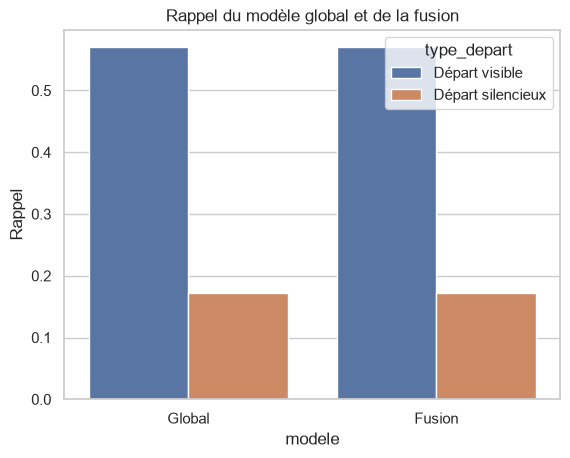

In [15]:
types_validation = np.where(
    train_prepare.loc[masque_validation, "target_visible"].values == 1,
    "Départ visible",
    np.where(
        train_prepare.loc[masque_validation, "target_silencieux"].values == 1,
        "Départ silencieux",
        "Pas de départ"
    )
)

lignes = []
for nom, pred in [("Global", pred_global_optimal), ("Fusion", pred_fusion)]:
    for type_depart in ["Départ visible", "Départ silencieux"]:
        masque = types_validation == type_depart
        lignes.append({
            "modele": nom,
            "type_depart": type_depart,
            "effectif": int(masque.sum()),
            "detectes": int(pred[masque].sum()),
            "rappel": pred[masque].mean()
        })

rappel_types = pd.DataFrame(lignes)
display(rappel_types)

sns.barplot(data=rappel_types, x="modele", y="rappel", hue="type_depart")
plt.title("Rappel du modèle global et de la fusion")
plt.ylabel("Rappel")
plt.show()

## 16. Importance du modèle spécialisé silencieux

Cette analyse montre les variables utilisées pour distinguer les départs silencieux des autres observations. Elle doit être interprétée avec prudence en raison du faible nombre de cas positifs.

,variable,importance
60,mecanisme_stagnation,35.679114
58,salaire_sous_reference,26.546560
64,score_anomalie,3.062119
12,engagement_actuel,2.997377
59,mecanisme_desengagement,2.785902
45,performance_moyenne,1.868959
35,age,1.863420
13,engagement_precedent,1.777041
61,cluster_rh,1.529467
3,poste,1.387878


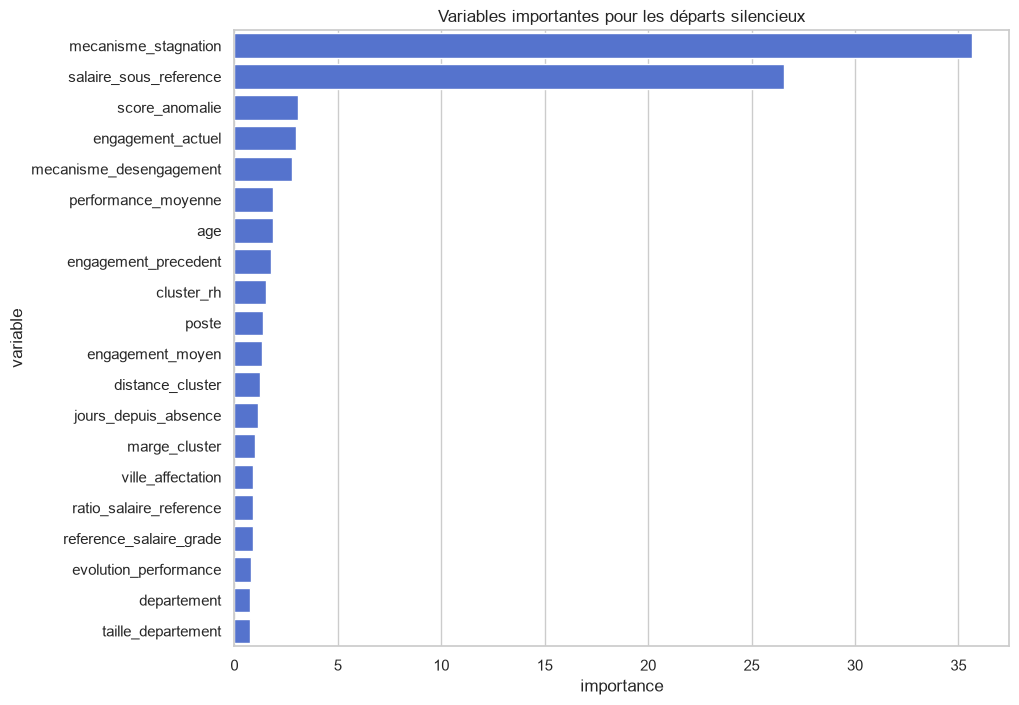

In [16]:
importance_silencieux = pd.DataFrame({
    "variable": X.columns,
    "importance": modele_silencieux.get_feature_importance()
}).sort_values("importance", ascending=False)

display(importance_silencieux.head(30))

plt.figure(figsize=(10, 8))
sns.barplot(data=importance_silencieux.head(20), x="importance", y="variable", color="royalblue")
plt.title("Variables importantes pour les départs silencieux")
plt.show()

## 17. Test de robustesse sur plusieurs seuils

Une solution robuste ne doit pas dépendre d’un seuil unique très précis. Le graphique compare le F1 du modèle global et de la fusion autour de leur optimum.

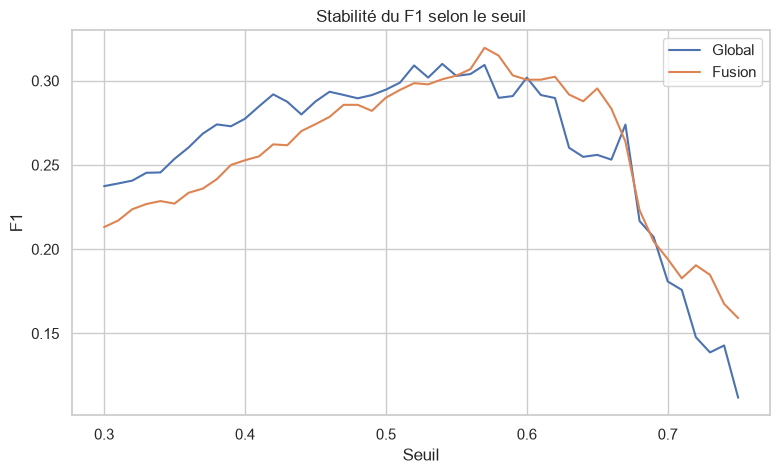

In [17]:
comparaison_seuils = []
for seuil in np.arange(0.30, 0.76, 0.01):
    comparaison_seuils.append({
        "seuil": seuil,
        "Global": f1_score(y_val_global, proba_global >= seuil),
        "Fusion": f1_score(y_val_global, proba_fusion >= seuil)
    })
comparaison_seuils = pd.DataFrame(comparaison_seuils)

plt.figure(figsize=(9, 5))
plt.plot(comparaison_seuils["seuil"], comparaison_seuils["Global"], label="Global")
plt.plot(comparaison_seuils["seuil"], comparaison_seuils["Fusion"], label="Fusion")
plt.title("Stabilité du F1 selon le seuil")
plt.xlabel("Seuil")
plt.ylabel("F1")
plt.legend()
plt.show()

## 18. Export des résultats

Aucune soumission n’est créée. Les résultats sont conservés pour comparaison avant l’ouverture de la plateforme.

In [18]:
comparaison.to_csv("../reports/comparaison_modele_global_specialistes.csv", index=False)
rappel_types.to_csv("../reports/rappel_specialistes_par_type_depart.csv", index=False)
importance_silencieux.to_csv("../reports/importance_modele_depart_silencieux.csv", index=False)
resultats_fusion_df.sort_values("f1", ascending=False).head(100).to_csv(
    "../reports/recherche_fusion_specialistes.csv", index=False
)

validation_export = pd.DataFrame({
    "id": train_prepare.loc[masque_validation, "id"].values,
    "target": y_val_global,
    "type_depart": types_validation,
    "proba_global": proba_global,
    "proba_visible": proba_visible,
    "proba_silencieux": proba_silencieux,
    "proba_fusion": proba_fusion,
    "prediction_fusion": pred_fusion
})
validation_export.to_csv("../reports/validation_modeles_specialises.csv", index=False)

print("Exports terminés dans reports.")

Exports terminés dans reports.


## Conclusion

L’architecture spécialisée ne sera retenue que si elle remplit trois conditions :

1. améliorer ou maintenir le F1 global ;
2. augmenter le rappel des départs silencieux ;
3. rester stable autour du seuil choisi.

Si le modèle silencieux n’apporte aucun gain, le résultat confirmera une limite informationnelle : les variables disponibles ne permettent pas de distinguer suffisamment ces départs avant leur réalisation.